# Section 6: SAGA and its accelerated variant on finite sums

Same data, $f_\star$ and baselines as in `Section1_experiments.ipynb`, for the two problems of Figure 1.2 that are finite sums, with the two methods of Section 6 on top. Everything is in this notebook.

- **SAGA** (6.3), with $\alpha=1/(3L)$ as in Theorem 6.1: one component gradient per iteration.
- **SSNM** (6.5), the accelerated SAGA of Section 6.3, with the step size of Corollary 6.4 and $\tau=n\alpha m/(1+\alpha m)$: two component gradients per iteration. The plotted point is $z_k$.
- **GD** (1.2) and **NAG** (1.4), with the parameters of Figure 1.2: $n$ component gradients per iteration.

**What is plotted.** $f(\cdot)-f_\star$ against the number of component gradients divided by $n$ (passes over the data), as in the experiments of Zhou et al. (2019). SAGA and SSNM spend their first pass computing the $n$ gradients at the starting point. They use $L=\max_iL_i$ and the strong convexity constant $m$ shared by the components (Section 6 assumes $f_i\in\mathcal F_{m,L}$), whereas GD and NAG use the constants $L_f\leq L$ and $m_f\geq m$ of the average $f$.

**When can acceleration help?** With $\kappa=L/m$, Theorem 6.1, Corollary 6.4 and the rate $1-\sqrt{m_f/L_f}$ of NAG give the number of passes that guarantees a factor $e$:

| | SAGA | SSNM | NAG |
|---|---|---|---|
| passes per factor $e$ | $\max\{4,\,3\kappa/n\}$ | $2\sqrt{3\kappa/n}$ if $\kappa\geq\tfrac43n$, about $4$ otherwise | $\sqrt{L_f/m_f}$ |

1. **Against SAGA: only if $\kappa\gg n$.** The predicted gain is $\tfrac{\sqrt3}2\sqrt{\kappa/n}$ when $\kappa\geq\tfrac43n$, and there is none otherwise: a factor 2 requires $\kappa\approx5n$, a factor 10 requires $\kappa\approx130n$. For the logistic loss on data normalized to $\|a_i\|=1$, $L=\tfrac14+\lambda$ and $m=\lambda$, so the common choice $\lambda=1/n$ gives $\kappa\approx n/4$: nothing to gain. This is why Zhou et al. (2019) run SSNM with $\lambda=10^{-6},10^{-7}$ on a9a ($n=32\,561$) and $\lambda=10^{-8},10^{-9}$ on covtype ($n=581\,012$), "since ill-condition is where all the accelerated first-order methods take effect". If their normalization is $\|a_i\|=1$ (the paper only says "normalized"), these are $\kappa/n\approx8$, $77$, $43$ and $430$.
2. **Against NAG: only if the components resemble each other.** When $m_f=m$, the predicted gain is $\sqrt{nL_f/L}\,/(2\sqrt3)$. The ratio $L_f/L$ lies between $1/n$ (components acting on orthogonal directions) and $1$ (identical components), so SSNM needs $nL_f/L\gg12$.
3. **Only if $m$ is the relevant constant.** SAGA's step size does not involve $m$, so SAGA can benefit from the strong convexity of the sum when it is larger than that of the components. SSNM uses $m$ in its step size and in $\tau$, and Theorem 6.3 needs every component to be $m$-strongly convex.
4. **Only beyond the first passes.** The comparisons above are between linear rates. SSNM spends two gradients per iteration, its iterate $z_k$ may first move away from $x_\star$ (the bound of Corollary 6.4 carries a factor $2/m$), and Zhou et al. (2019) already note that accelerated methods can be slower in the first passes.

**Experiments.** Each one isolates one of the first three points.

| | (a) three regimes | (b) problem (ii) of Figure 1.2 | (c) problem (i) of Figure 1.2, plus a small ridge |
|---|---|---|---|
| data | sonar, rows normalized to $\|a_i\|=1$ | sonar, as in Figure 1.2 | diabetes, as in Figure 1.2 |
| $f_i(x)$ | $\log(1+e^{-y_i\langle a_i,x\rangle})+\frac\lambda2\|x\|^2$ | same | $\frac12(\langle a_i,x\rangle-b_i)^2+\frac\lambda2\|x\|^2$ |
| $\lambda$ | $1/(4rn)$ with $r=\tfrac14,\ 8,\ 80$ | $1/n$ | $10^{-4}$ |
| $\kappa/n$ | $\approx r$ | $66$ | $1126$, but $13$ with the strong convexity of the sum |
| $nL_f/L$ | $40$ | $9.7$ | $36$ |
| illustrates | point 1 | point 2 | point 3 |

Problem (iii) of Figure 1.2 (log-sum-exp) is not a finite sum. The whole notebook runs in less than a minute.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit
from sklearn.datasets import load_diabetes

# Sonar data (UCI). Replace by the path of a local copy if you are offline.
SONAR_FILE = "https://archive.ics.uci.edu/ml/machine-learning-databases/undocumented/connectionist-bench/sonar/sonar.all-data"

## The two full-gradient methods of Section 1

- GD (1.2): $x_{k+1} = x_k - \alpha\nabla f(x_k)$.
- NAG (1.4): $x_{k+1} = y_k - \alpha\nabla f(y_k)$, $\ y_{k+1} = x_{k+1} + \beta_k(x_{k+1} - x_k)$, with $y_0 = x_0$.

Each function returns the values $f(x_0), f(x_1), \dots, f(x_N)$. One iteration is one pass over the data.

In [2]:
def gd(f, grad, x0, alpha, n_iter):
    x = x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x = x - alpha * grad(x)
        values.append(f(x))
    return np.array(values)


def nag(f, grad, x0, alpha, beta, n_iter):
    # beta is either a number or a function k -> beta_k
    x, y = x0.copy(), x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x_next = y - alpha * grad(y)
        beta_k = beta(k) if callable(beta) else beta
        y = x_next + beta_k * (x_next - x)
        x = x_next
        values.append(f(x))
    return np.array(values)

## The two methods of Section 6

Both methods keep, for each component, a stored point $\phi_{i,k}$ (the starting point when $k=0$) and its gradient $\nabla f_i(\phi_{i,k})$.

- SAGA (6.3): sample $i_k$; $\ d_k=\nabla f_{i_k}(x_k)-\nabla f_{i_k}(\phi_{i_k,k})+\tfrac1n\sum_j\nabla f_j(\phi_{j,k})$; $\ x_{k+1}=x_k-\alpha d_k$; $\ \phi_{i_k,k+1}=x_k$.
- SSNM (6.5): sample $i_k$; $\ y_k=\tau z_k+(1-\tau)\phi_{i_k,k}$; $\ d_k$ as above with $\nabla f_{i_k}(y_k)$ in place of $\nabla f_{i_k}(x_k)$; $\ w_k=y_k-\phi_{i_k,k}+\tfrac1n\sum_j\phi_{j,k}$; $\ z_{k+1}=(z_k+\alpha m\,w_k-\alpha d_k)/(1+\alpha m)$; sample $j_k$; $\ \phi_{j_k,k+1}=\tau z_{k+1}+(1-\tau)\phi_{j_k,k}$.

Each function returns the values of $f$ after $0,1,\dots,N$ passes, a pass being $n$ component gradients: $n$ iterations of SAGA, $n/2$ iterations of SSNM. The first pass computes the $n$ gradients at the starting point. The tables hold full gradients, which is fine at this size (for linear models, $n$ scalars are enough, see Section 6.2).

`predicted_passes` returns the number of passes per factor 10 guaranteed by the worst-case rates, and `observed_passes` measures it on a run, between the levels $10^{-4}$ and $10^{-10}$ of $f-f_\star$.

In [3]:
def saga(f, grad_i, x0, n, alpha, n_pass, rng):
    # SAGA (6.3). table[i] = grad f_i(phi_i), gbar = average of the table.
    x = x0.copy()
    table = np.array([grad_i(i, x0) for i in range(n)])
    values = [f(x), f(x)]                                   # first pass: the n gradients at x_0
    for p in range(n_pass - 1):
        gbar = table.mean(axis=0)
        for i in rng.integers(n, size=n):
            g = grad_i(i, x)
            x = x - alpha * (g - table[i] + gbar)
            gbar += (g - table[i]) / n
            table[i] = g
        values.append(f(x))
    return np.array(values)


def ssnm_step_size(n, L, m):
    # Corollary 6.4
    return 1 / np.sqrt(3 * m * n * L) if n <= 0.75 * L / m else 1 / (2 * m * n)


def ssnm(f, grad_i, z0, n, alpha, m, n_pass, rng, at_stored_points=False):
    # SSNM (6.5). phi[i] = stored points, table[i] = grad f_i(phi_i), pbar and gbar = their averages.
    # Returns the values of f at z_k, or at the average of the stored points if at_stored_points is True.
    tau = n * alpha * m / (1 + alpha * m)
    z = z0.copy()
    phi = np.tile(z0, (n, 1))
    table = np.array([grad_i(i, z0) for i in range(n)])
    values = [f(z), f(z)]                                   # first pass: the n gradients at z_0
    for p in range(n_pass - 1):
        pbar, gbar = phi.mean(axis=0), table.mean(axis=0)
        for i, j in rng.integers(n, size=(n // 2, 2)):      # two component gradients per iteration
            y = tau * z + (1 - tau) * phi[i]
            d = grad_i(i, y) - table[i] + gbar
            w = y - phi[i] + pbar
            z = (z + alpha * m * w - alpha * d) / (1 + alpha * m)
            new = tau * z + (1 - tau) * phi[j]
            g = grad_i(j, new)
            pbar += (new - phi[j]) / n
            gbar += (g - table[j]) / n
            phi[j], table[j] = new, g
        values.append(f(phi.mean(axis=0)) if at_stored_points else f(z))
    return np.array(values)


def run_methods(f, grad, grad_i, x0, n, L, m, L_f, m_f, n_pass, seed=0):
    # GD and NAG with the constants (L_f, m_f) of f, as in Figure 1.2; SAGA and SSNM with the constants (L, m) of the components.
    rL, rm = np.sqrt(L_f), np.sqrt(m_f)
    return {
        "GD": gd(f, grad, x0, 1 / L_f, n_pass),
        "NAG": nag(f, grad, x0, 1 / L_f, (rL - rm) / (rL + rm), n_pass),
        "SAGA": saga(f, grad_i, x0, n, 1 / (3 * L), n_pass, np.random.default_rng(seed)),
        "SSNM": ssnm(f, grad_i, x0, n, ssnm_step_size(n, L, m), m, n_pass, np.random.default_rng(seed)),
    }


def predicted_passes(n, L, m, L_f, m_f):
    # Passes per factor 10 guaranteed by the worst-case rates: contraction factor per iteration and gradients per iteration.
    rates = {
        "GD": (1 - m_f / L_f, n),
        "NAG": (1 - np.sqrt(m_f / L_f), n),
        "SAGA": (1 - min(1 / (4 * n), m / (3 * L)), 1),               # Theorem 6.1
        "SSNM": (1 / (1 + ssnm_step_size(n, L, m) * m), 2),           # Corollary 6.4
    }
    return {name: cost * np.log(10) / -np.log(rho) / n for name, (rho, cost) in rates.items()}


def observed_passes(gap, high=1e-4, low=1e-10):
    # Passes per factor 10 between the first time the gap is below `high` and the first time it is below `low`
    # (or the end of the run, if at least one factor 10 was gained by then).
    if not np.any(gap <= high):
        return np.nan
    start = np.argmax(gap <= high)
    stop = np.argmax(gap <= low) if np.any(gap <= low) else len(gap) - 1
    decades = np.log10(gap[start] / max(gap[stop], 1e-16))
    return (stop - start) / decades if decades >= 1 else np.nan


def report(gaps, predicted):
    print("  passes per factor 10     predicted   observed")
    for name, gap in gaps.items():
        observed = observed_passes(gap)
        print(f"    {name:20s} {predicted[name]:10.1f} " + (f"{observed:10.1f}" if np.isfinite(observed) else "         -"))

## Computing $f_\star$

Closed form for the ridge problem. For the logistic problems $d$ is small, so a trust-region Newton method (exact Hessians) reaches $f_\star$ to machine precision.

In [4]:
def solve_with_newton(f, grad, hess, x0):
    res = minimize(f, x0, jac=grad, hess=hess, method="trust-exact", options={"gtol": 1e-13, "maxiter": 1000})
    print(f"  Newton: {res.nit} iterations, |grad f(x*)| = {np.linalg.norm(grad(res.x)):.1e}")
    return res.x

## Data

Same data and preprocessing as in `Section1_experiments.ipynb`. For experiment (a), the rows of the sonar matrix are then normalized to unit norm.

In [5]:
def standardize(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)


def add_intercept(Z):
    return np.hstack([Z, np.ones((Z.shape[0], 1))])


# Diabetes (Efron, Hastie, Johnstone and Tibshirani 2004): raw data shipped with scikit-learn
diabetes = load_diabetes(scaled=False)
A_diabetes = add_intercept(standardize(diabetes.data))
b_diabetes = standardize(diabetes.target)

# Sonar (Gorman and Sejnowski 1988): 60 features, label "M" (mine) or "R" (rock)
sonar = pd.read_csv(SONAR_FILE, header=None)
A_sonar = add_intercept(standardize(sonar.iloc[:, :60].to_numpy(dtype=float)))
y_sonar = np.where(sonar.iloc[:, 60] == "M", 1.0, -1.0)
A_sonar_unit = A_sonar / np.linalg.norm(A_sonar, axis=1, keepdims=True)

print("diabetes:", A_diabetes.shape, "  sonar:", A_sonar.shape)

diabetes: (442, 11)   sonar: (208, 61)


## The finite sums

- Logistic regression: $f_i(x)=\log(1+e^{-y_i\langle a_i,x\rangle})+\frac\lambda2\|x\|^2$, so $L=\max_i\|a_i\|^2/4+\lambda$ and $m=\lambda$ for the components, and $L_f=\lambda_{\max}(A^\top A)/(4n)+\lambda$, $m_f=\lambda$ for the average (as in Figure 1.2).
- Ridge regression: $f_i(x)=\frac12(\langle a_i,x\rangle-b_i)^2+\frac\lambda2\|x\|^2$, so $L=\max_i\|a_i\|^2+\lambda$ and $m=\lambda$ for the components, and $L_f=\lambda_{\max}(A^\top A)/n+\lambda$, $m_f=\lambda_{\min}(A^\top A)/n+\lambda$ for the average.

In [6]:
def make_logistic(A, y, lam):
    n, d = A.shape
    def f(x):
        return np.mean(np.logaddexp(0, -y * (A @ x))) + lam / 2 * x @ x
    def grad(x):
        return -A.T @ (y * expit(-y * (A @ x))) / n + lam * x
    def hess(x):
        s = expit(A @ x)
        return A.T @ (A * (s * (1 - s))[:, None]) / n + lam * np.eye(d)
    def grad_i(i, x):
        return -y[i] * expit(-y[i] * (A[i] @ x)) * A[i] + lam * x
    return f, grad, hess, grad_i


def make_ridge(A, b, lam):
    n = A.shape[0]
    def f(x):
        return np.sum((A @ x - b) ** 2) / (2 * n) + lam / 2 * x @ x
    def grad(x):
        return A.T @ (A @ x - b) / n + lam * x
    def grad_i(i, x):
        return (A[i] @ x - b[i]) * A[i] + lam * x
    return f, grad, grad_i


def logistic_experiment(A, y, lam, n_pass):
    n, d = A.shape
    f, grad, hess, grad_i = make_logistic(A, y, lam)
    L, m = np.max(np.sum(A ** 2, axis=1)) / 4 + lam, lam
    L_f, m_f = np.linalg.eigvalsh(A.T @ A)[-1] / (4 * n) + lam, lam
    f_star = f(solve_with_newton(f, grad, hess, np.zeros(d)))
    print(f"  lambda = {lam:.3g}:  L = {L:.3g}, m = {m:.3g}, kappa/n = {L / m / n:.3g};  L_f = {L_f:.3g}, n L_f/L = {n * L_f / L:.3g}")
    values = run_methods(f, grad, grad_i, np.zeros(d), n, L, m, L_f, m_f, n_pass)
    gaps = {name: v - f_star for name, v in values.items()}
    report(gaps, predicted_passes(n, L, m, L_f, m_f))
    return gaps

## (a) Three regimes: logistic regression on sonar with normalized rows

All components have $L=\tfrac14+\lambda$ and $m=\lambda$, and $\lambda=1/(4rn)$ gives $\kappa/n\approx r$. The value $r=\tfrac14$ is the usual $\lambda=1/n$; $r=8$ and $r=80$ are the ratios of the two a9a experiments of Zhou et al. (2019), see point 1 above. The predicted gains of SSNM over SAGA are $1$, $2.4$ and $7.7$; over NAG, $\sqrt{40}/(2\sqrt3)\approx1.8$ in the last two cases.

In [7]:
n = A_sonar_unit.shape[0]
gaps_regimes = {}
for r, n_pass in [(0.25, 60), (8, 250), (80, 800)]:
    print(f"kappa/n = {r}")
    gaps_regimes[r] = logistic_experiment(A_sonar_unit, y_sonar, 1 / (4 * r * n), n_pass)

kappa/n = 0.25
  Newton: 6 iterations, |grad f(x*)| = 1.2e-14
  lambda = 0.00481:  L = 0.255, m = 0.00481, kappa/n = 0.255;  L_f = 0.0529, n L_f/L = 43.2
  passes per factor 10     predicted   observed
    GD                         24.2       10.2
    NAG                         6.4        3.1
    SAGA                        9.2        2.3
    SSNM                        9.2        4.9
kappa/n = 8
  Newton: 9 iterations, |grad f(x*)| = 4.6e-17
  lambda = 0.00015:  L = 0.25, m = 0.00015, kappa/n = 8;  L_f = 0.0482, n L_f/L = 40.1
  passes per factor 10     predicted   observed
    GD                        737.7          -
    NAG                        40.1       19.5
    SAGA                       55.3       22.5
    SSNM                       22.6       12.3
kappa/n = 80
  Newton: 11 iterations, |grad f(x*)| = 2.1e-17
  lambda = 1.5e-05:  L = 0.25, m = 1.5e-05, kappa/n = 80;  L_f = 0.0481, n L_f/L = 40
  passes per factor 10     predicted   observed
    GD                       7366

## (b) Problem (ii) of Figure 1.2 as a finite sum

The $\ell_2$-regularized logistic regression of Figure 1.2: standardized features, $\lambda=1/n$. The rows are not normalized, and the largest component constant $L=\max_i\|a_i\|^2/4+\lambda$ is about 21 times $L_f$. Then $\kappa/n\approx66$, so SSNM is predicted to be 7 times faster than SAGA, but $nL_f/L\approx9.7<12$: it is not predicted to beat NAG (predicted ratio $0.9$).

In [8]:
print("sonar, standardized features")
gaps_logistic = logistic_experiment(A_sonar, y_sonar, 1 / A_sonar.shape[0], n_pass=600)

sonar, standardized features
  Newton: 7 iterations, |grad f(x*)| = 1.4e-11
  lambda = 0.00481:  L = 65.7, m = 0.00481, kappa/n = 65.7;  L_f = 3.06, n L_f/L = 9.68
  passes per factor 10     predicted   observed
    GD                       1462.9          -
    NAG                        56.9       26.9
    SAGA                      453.9      163.5
    SSNM                       64.7       30.9


## (c) Problem (i) of Figure 1.2 with a small ridge: when the sum is better conditioned than its components

The components $\frac12(\langle a_i,x\rangle-b_i)^2$ of the least-squares problem of Figure 1.2 are not strongly convex. Adding $\frac\lambda2\|x\|^2$ with $\lambda=10^{-4}$ puts them in $\mathcal F_{m,L}$ with $m=\lambda$, hence $\kappa/n\approx1126$, deep in the regime where the worst-case analysis favors acceleration. The sum, however, is strongly convex with $m_f=\lambda_{\min}(A^\top A)/n+\lambda\approx 87\lambda$.

- SSNM is first run as Corollary 6.4 prescribes, with $m=\lambda$.
- It is then run with $m_f$ in place of $m$ (label "SSNM, $m_f$"). Theorem 6.3 does not cover this choice, since the components are not $m_f$-strongly convex.

The table also gives the predictions obtained by replacing $m$ by $m_f$ in Theorem 6.1 and Corollary 6.4, which are not guarantees either.

In [9]:
A, b = A_diabetes, b_diabetes
n, d = A.shape
lam = 1e-4
f, grad, grad_i = make_ridge(A, b, lam)

eigenvalues = np.linalg.eigvalsh(A.T @ A / n)
L, m = np.max(np.sum(A ** 2, axis=1)) + lam, lam
L_f, m_f = eigenvalues[-1] + lam, eigenvalues[0] + lam
f_star = f(np.linalg.solve(A.T @ A / n + lam * np.eye(d), A.T @ b / n))
print(f"diabetes, lambda = {lam:.3g}:  L = {L:.3g}, m = {m:.3g}, kappa/n = {L / m / n:.4g};  L_f = {L_f:.3g}, m_f = {m_f:.3g}, L/(m_f n) = {L / m_f / n:.3g}, n L_f/L = {n * L_f / L:.3g}")

n_pass = 500
values = run_methods(f, grad, grad_i, np.zeros(d), n, L, m, L_f, m_f, n_pass)
values["SSNM, m_f"] = ssnm(f, grad_i, np.zeros(d), n, ssnm_step_size(n, L, m_f), m_f, n_pass, np.random.default_rng(0))
gaps_ridge = {name: v - f_star for name, v in values.items()}

predicted = predicted_passes(n, L, m, L_f, m_f)
predicted["SSNM, m_f"] = predicted_passes(n, L, m_f, L_f, m_f)["SSNM"]
report(gaps_ridge, predicted)
print(f"  SAGA with m_f in place of m in Theorem 6.1: {predicted_passes(n, L, m_f, L_f, m_f)['SAGA']:.1f} passes per factor 10")

diabetes, lambda = 0.0001:  L = 49.8, m = 0.0001, kappa/n = 1126;  L_f = 4.02, m_f = 0.00866, L/(m_f n) = 13, n L_f/L = 35.7
  passes per factor 10     predicted   observed
    GD                       1068.8          -
    NAG                        48.5       28.2
    SAGA                     7780.0       44.9
    SSNM                      267.7      254.7
    SSNM, m_f                  28.8       16.2
  SAGA with m_f in place of m in Theorem 6.1: 89.8 passes per factor 10


## Figures

Gaps below $10^{-16}$ (machine precision, possibly negative) are drawn at $10^{-16}$. One seed is shown; the next section looks at other seeds.

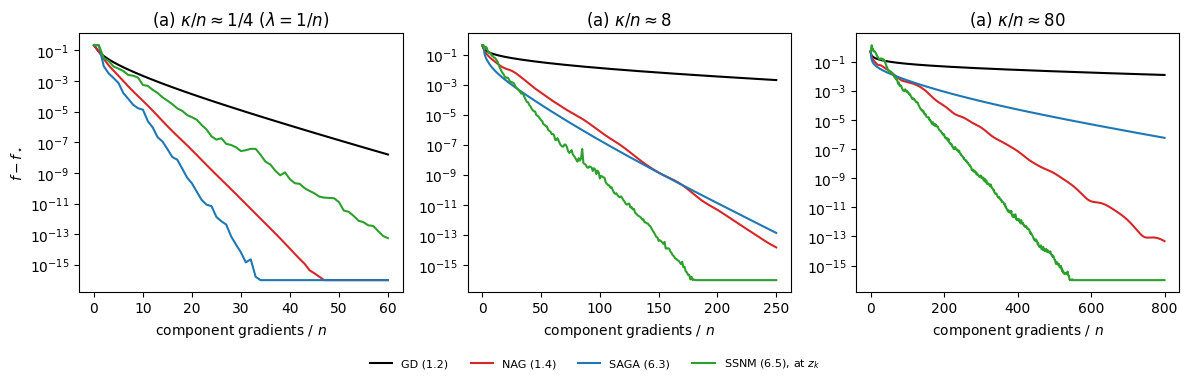

In [10]:
styles = {
    "GD": dict(color="black", label="GD (1.2)"),
    "NAG": dict(color="tab:red", label="NAG (1.4)"),
    "SAGA": dict(color="tab:blue", label="SAGA (6.3)"),
    "SSNM": dict(color="tab:green", label=r"SSNM (6.5), at $z_k$"),
    "SSNM, m_f": dict(color="tab:green", linestyle="--", label=r"SSNM (6.5) with $m_f$ in place of $m$"),
    "SSNM, stored": dict(color="tab:olive", label=r"SSNM (6.5), at the average of the $\phi_{i,k}$"),
}


def plot_gaps(ax, gaps, title):
    for name, gap in gaps.items():
        ax.semilogy(np.maximum(gap, 1e-16), **styles[name])
    ax.set_title(title)
    ax.set_xlabel("component gradients / $n$")


def legend_below(fig, ax):
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=len(labels), fontsize=8, frameon=False)


fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
titles = {0.25: r"(a) $\kappa/n\approx 1/4$ ($\lambda=1/n$)", 8: r"(a) $\kappa/n\approx 8$", 80: r"(a) $\kappa/n\approx 80$"}
for ax, (r, gaps) in zip(axes, gaps_regimes.items()):
    plot_gaps(ax, gaps, titles[r])
axes[0].set_ylabel(r"$f - f_\star$")
fig.tight_layout()
legend_below(fig, axes[0])
# fig.savefig("fig_section6_regimes.pdf", bbox_inches="tight")
plt.show()

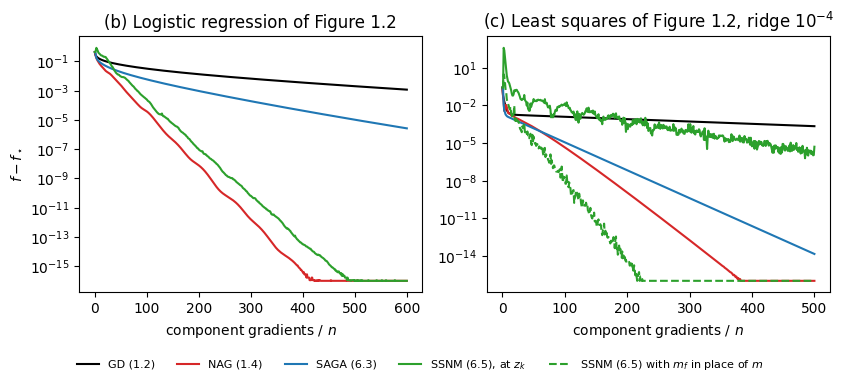

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
plot_gaps(axes[0], gaps_logistic, "(b) Logistic regression of Figure 1.2")
plot_gaps(axes[1], gaps_ridge, r"(c) Least squares of Figure 1.2, ridge $10^{-4}$")
axes[0].set_ylabel(r"$f - f_\star$")
fig.tight_layout()
legend_below(fig, axes[1])
# fig.savefig("fig_section6_problems.pdf", bbox_inches="tight")
plt.show()

## Which point to report for SSNM?

In Nesterov's method (2.34), function values are controlled along the sequence $x_k$, and only the distance to $x_\star$ is controlled along $z_k$. In SSNM, the sequence $z_k$ plays the role of the latter and the stored points play the role of $x_k$: the potential of Theorem 6.3 contains $\|z_k-x_\star\|^2$ and the divergences $B_i(\phi_{i,k})$, and the bound of Corollary 6.4 on $\|z_N-x_\star\|^2$ carries the factor $\tfrac2m(f(z_0)-f_\star)$. The curves above are at $z_k$. Here they are compared with $f$ at the average of the stored points, $\bar\phi_k=\tfrac1n\sum_i\phi_{i,k}$, on (b) and on (c) with $m=\lambda$ (same seed, hence same run).

  Newton: 7 iterations, |grad f(x*)| = 1.4e-11
  (b) largest value of (f - f_star)/(f(z_0) - f_star):      1.9 at z_k,  1.00 at the average of the stored points;  gaps after 300 passes: 6.5e-11 and 2.0e-10
  (c) largest value of (f - f_star)/(f(z_0) - f_star):   1486.5 at z_k,  1.00 at the average of the stored points;  gaps after 300 passes: 8.2e-05 and 3.3e-05


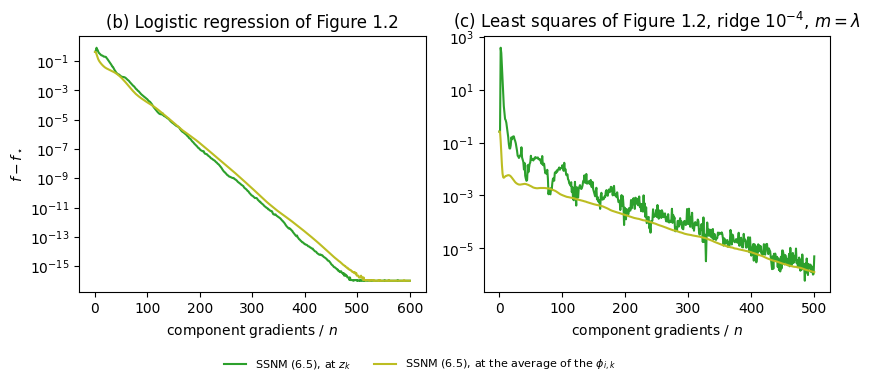

In [12]:
# (b): logistic regression of Figure 1.2
A, y = A_sonar, y_sonar
n, d = A.shape
lam = 1 / n
f, grad, hess, grad_i = make_logistic(A, y, lam)
L, m = np.max(np.sum(A ** 2, axis=1)) / 4 + lam, lam
f_star = f(solve_with_newton(f, grad, hess, np.zeros(d)))
stored_logistic = ssnm(f, grad_i, np.zeros(d), n, ssnm_step_size(n, L, m), m, 600, np.random.default_rng(0), at_stored_points=True) - f_star

# (c): least squares of Figure 1.2 with the ridge, m = lambda
A, b = A_diabetes, b_diabetes
n, d = A.shape
lam = 1e-4
f, grad, grad_i = make_ridge(A, b, lam)
L, m = np.max(np.sum(A ** 2, axis=1)) + lam, lam
f_star = f(np.linalg.solve(A.T @ A / n + lam * np.eye(d), A.T @ b / n))
stored_ridge = ssnm(f, grad_i, np.zeros(d), n, ssnm_step_size(n, L, m), m, 500, np.random.default_rng(0), at_stored_points=True) - f_star

for label, at_z, at_stored in [("(b)", gaps_logistic["SSNM"], stored_logistic), ("(c)", gaps_ridge["SSNM"], stored_ridge)]:
    print(f"  {label} largest value of (f - f_star)/(f(z_0) - f_star):  {np.max(at_z) / at_z[0]:7.1f} at z_k,  {np.max(at_stored) / at_stored[0]:4.2f} at the average of the stored points;"
          f"  gaps after 300 passes: {at_z[300]:.1e} and {at_stored[300]:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
for ax, title, at_z, at_stored in [(axes[0], "(b) Logistic regression of Figure 1.2", gaps_logistic["SSNM"], stored_logistic),
                                   (axes[1], r"(c) Least squares of Figure 1.2, ridge $10^{-4}$, $m=\lambda$", gaps_ridge["SSNM"], stored_ridge)]:
    plot_gaps(ax, {"SSNM": at_z, "SSNM, stored": at_stored}, title)
axes[0].set_ylabel(r"$f - f_\star$")
fig.tight_layout()
legend_below(fig, axes[0])
plt.show()

## Other seeds

Zhou et al. (2019) report that SSNM is "somewhat unstable" compared with the other methods, which they attribute to its two samples per iteration. Number of passes needed to reach $f-f_\star\leq10^{-6}$ in the middle regime of (a), over ten seeds:

In [13]:
A, y = A_sonar_unit, y_sonar
n, d = A.shape
lam = 1 / (4 * 8 * n)
f, grad, hess, grad_i = make_logistic(A, y, lam)
L, m = 0.25 + lam, lam
f_star = f(solve_with_newton(f, grad, hess, np.zeros(d)))

def first_pass_below(values, level):
    below = values - f_star <= level
    return int(np.argmax(below)) if below.any() else np.inf

passes = {"SAGA": [], "SSNM": []}
for seed in range(10):
    passes["SAGA"].append(first_pass_below(saga(f, grad_i, np.zeros(d), n, 1 / (3 * L), 150, np.random.default_rng(seed)), 1e-6))
    passes["SSNM"].append(first_pass_below(ssnm(f, grad_i, np.zeros(d), n, ssnm_step_size(n, L, m), m, 150, np.random.default_rng(seed)), 1e-6))
for name, p in passes.items():
    print(f"  {name}: between {min(p)} and {max(p)} passes (median {int(np.median(p))})")

  Newton: 9 iterations, |grad f(x*)| = 4.6e-17
  SAGA: between 85 and 86 passes (median 85)
  SSNM: between 57 and 63 passes (median 60)


## What the experiments show

The numbers are those of the tables printed above (passes per factor 10, measured between $10^{-4}$ and $10^{-10}$).

- **(a), $\kappa/n\approx\tfrac14$: no gain, and a loss in practice.** The two worst-case bounds coincide (9.2 passes per factor 10). SAGA needs 2.3 passes and SSNM 4.9: with $\lambda=1/n$ on normalized data, the accelerated method is twice slower.
- **(a), $\kappa/n\approx8$ and $80$: the predicted gains are there.** SSNM is asymptotically 1.8 and 5.9 times faster than SAGA (predicted: 2.4 and 7.7), and 1.6 and 1.8 times faster than NAG (predicted: 1.8). Every method is about twice as fast as its worst-case bound (between 1.8 and 2.7 times), so the ratios between the bounds are a good guide. To reach $10^{-6}$ with $\kappa/n\approx80$: 198 passes for SSNM, 325 for NAG, 750 for SAGA.
- **(a), first passes.** SAGA is ahead of SSNM during the first 29 passes for $\kappa/n\approx8$ (down to a gap of about $10^{-3}$) and the first 62 passes for $\kappa/n\approx80$ (down to about $10^{-2}$). This is the behavior that Zhou et al. (2019) report on a9a. Acceleration pays off at moderate and high accuracy.
- **(b): heterogeneous components.** This is $\lambda=1/n$ again, but without normalizing the rows, so that $\kappa/n\approx66$: SSNM is 5.3 times faster than SAGA (predicted: 7). It is slightly slower than NAG, 30.9 against 26.9 passes per factor 10, a ratio of 0.87 for a predicted 0.88, because the largest component constant is 21 times that of the average.
- **(c): the constant $m$ matters.** Run as prescribed, with $m=\lambda$, SSNM needs 255 passes per factor 10, essentially its worst-case bound (268). SAGA needs 45: it is 5.7 times faster, far from its own bound with $m=\lambda$ (7780) and within a factor 2 of the same formula with $m_f$ (90). With $m_f$ in place of $m$, SSNM needs 16 passes per factor 10: 2.8 times faster than SAGA and 1.7 times faster than NAG, as point 2 predicts for $nL_f/L\approx36$, but without a guarantee from Theorem 6.3.
- **Reporting point.** At $z_k$, the gap first rises to 1.9 times its initial value in (b) and to about 1500 times in (c), which the factor $\tfrac2m$ of Corollary 6.4 allows. At the average of the stored points it never exceeds its initial value in these two runs, and the two points then decrease at the same rate.
- **Seeds.** The spread is small: 57 to 63 passes for SSNM and 85 to 86 for SAGA in the middle regime of (a).

**In short.** On a finite sum, SSNM is worth its two gradients per iteration and its additional parameter when (i) $\kappa\gg n$, which for the logistic loss on normalized data means $\lambda\ll1/(4n)$; (ii) $m$ is known and is the curvature that actually limits the sum; (iii) more than a few digits are needed. It then also beats NAG when (iv) $nL_f/L\gg12$. When (i), (ii) or (iii) fails, SAGA, which needs neither $m$ nor a second gradient, is at least as good.

## Save into .dat

In [14]:
import os

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

files = {
    "section6_logistic_sonar_unit_r025": gaps_regimes[0.25],
    "section6_logistic_sonar_unit_r8": gaps_regimes[8],
    "section6_logistic_sonar_unit_r80": gaps_regimes[80],
    "section6_logistic_sonar": gaps_logistic,
    "section6_ridge_diabetes": gaps_ridge,
}
columns = {"GD": "gd_f", "NAG": "nag_f", "SAGA": "saga_f", "SSNM": "ssnm_f", "SSNM, m_f": "ssnm_mf_f"}

for name, gaps in files.items():
    k = np.arange(len(gaps["GD"]))                         # passes over the data
    header = " ".join(["k"] + [columns[method] for method in gaps])
    fmt = ["%d"] + ["%.6e"] * len(gaps)
    table = np.column_stack([k] + [np.maximum(gap, 1e-16) for gap in gaps.values()])
    np.savetxt(f"{DATA_DIR}/{name}.dat", table, header=header, fmt=fmt, comments="")

    # thin copy: every pass up to k = 50, then about 300 points, and the last one
    step = max(1, len(k) // 300)
    keep = (k <= 50) | (k % step == 0) | (k == k[-1])
    np.savetxt(f"{DATA_DIR}/{name}_thin.dat", table[keep], header=header, fmt=fmt, comments="")
    print(f"{DATA_DIR}/{name}.dat: {len(k)} rows, thin copy: {keep.sum()} rows")

data/section6_logistic_sonar_unit_r025.dat: 61 rows, thin copy: 61 rows
data/section6_logistic_sonar_unit_r8.dat: 251 rows, thin copy: 251 rows
data/section6_logistic_sonar_unit_r80.dat: 801 rows, thin copy: 426 rows
data/section6_logistic_sonar.dat: 601 rows, thin copy: 326 rows
data/section6_ridge_diabetes.dat: 501 rows, thin copy: 501 rows
